<a href="https://colab.research.google.com/github/wonjun605/Digital-Image-Processing/blob/main/Untitled0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import cv2
from google.colab.patches import cv2_imshow
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


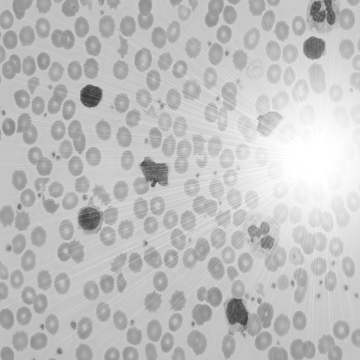

In [6]:
import cv2
from google.colab.patches import cv2_imshow

# 이미지 불러오기 및 RGB 변환
img = cv2.imread('/content/gdrive/My Drive/ColabIP26/Images/cell-bright.bmp')
RGB_Img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# 그레이스케일로 변환
gImg1 = cv2.cvtColor(RGB_Img, cv2.COLOR_RGB2GRAY)

# 변환된 그레이 이미지 출력
cv2_imshow(gImg1)

In [36]:
N = 10

dimh = np.int32(gImg1.shape[0]/N)
dimw = np.int32(gImg1.shape[1]/N)
print(dimh, dimw)

resh = np.int32(gImg1.shape[0] % N)
resw = np.int32(gImg1.shape[1] % N)
print(resh,resw)

meanImg = np.zeros((N,N))
outImg = np.zeros((gImg1.shape[0], gImg1.shape[1]))

36 36
0 0


In [37]:
def mean_func(img, dimh, dimw, resh, resw):
  sum = np.int32(0)
  count = 0
  avg = 0

  for i in range(h, h + dimh):
    for j in range(w, w + dimh):
      sum += img[i, j]
      count += 1

  avg = np.int32(sum / count)
  return avg

In [38]:
for h in range(0, gImg1.shape[0] - resh, dimh):
  for w in range(0, gImg1.shape[1] - resw, dimw):
    meanImg[np.int32(h/dimh), np.int32(w/dimw)] = mean_func(gImg1, dimh, dimw,h , w)

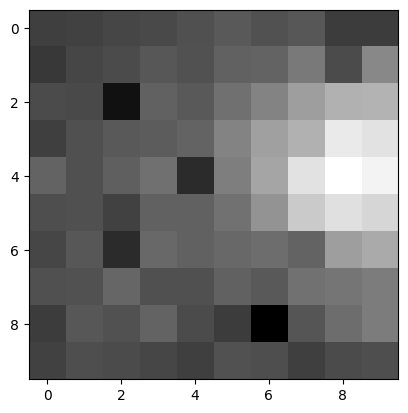

In [39]:
plt.imshow(meanImg, cmap='gray')

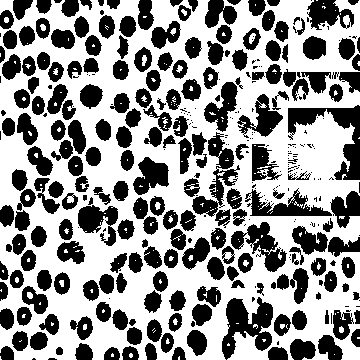

In [40]:
for h in range(0, gImg1.shape[0] - resh):
  for w in range(0, gImg1.shape[1] - resw):
    if(gImg1[h, w] > meanImg[np.int32(h/dimh), np.int32(w/dimw)]):
      outImg[h, w] = 255
    else:
      outImg[h, w] = 0

cv2_imshow(outImg)